# Steady-state finite-element capture analysis

This notebook constructs a periodic fluid unit cell above a continuous sensor height field, solves the steady diffusion equation, and compares the perfectly absorbing accessibility limit with finite Robin reactivity. The FEM implementation is in `utils/fea_capture.py`; the mathematical formulation is in `fea_capture_formulation.tex`.

## 1. Check the FEniCSx environment

FEniCSx, PETSc, MPI, and `dolfinx_mpc` must be installed as mutually compatible builds. A dedicated conda environment or the published `dolfinx_mpc` container is recommended. The repository's ordinary Python environment does not need these optional packages.

In [96]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "utils").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import utils.fea_capture as fea_capture
importlib.reload(fea_capture)

from utils.fea_capture import (
    DiffusionCaptureConfig,
    FEMeshConfig,
    calculate_equilibrium_surface_delivery,
    create_height_field_mesh,
    cylindrically_curved_sheet_height,
    fit_planar_bulk_resistance,
    height_corrected_surface_accessibility,
    planar_height,
    require_fenicsx,
    result_summary,
    robin_velocity_from_kon_density,
    sinusoidal_height,
    solve_steady_capture,
    spherical_bowl_height,
    write_fea_result,
)

# FEniCSx initialization is temporarily disabled while testing equilibrium delivery.
# require_fenicsx()
# from mpi4py import MPI
# from dolfinx import mesh as dolfinx_mesh
# COMM = MPI.COMM_WORLD
# print(f"FEniCSx environment ready on {COMM.size} MPI rank(s).")

## 2. Define transport, receptor, and mesh parameters

`C_BULK_MOL_M3` may be set to 1 because the steady equation and Robin boundary are linear in concentration. The resulting `capture_rate_m3_s = capture_flux/Cbulk` is independent of that normalization.

In [97]:
nm = 1e-9

L_X_M = 100 * nm
L_Y_M = 100 * nm
TOP_Z_M = 60 * nm
D_M2_S = 1e-11
C_BULK_MOL_M3 = 1.0e-6

K_ON_M_INV_S = 1e7
RECEPTOR_DENSITY_M2 = 5e16
KAPPA_M_S = robin_velocity_from_kon_density(K_ON_M_INV_S, RECEPTOR_DENSITY_M2)

MESH = FEMeshConfig(
    Lx_m=L_X_M, Ly_m=L_Y_M, top_z_m=TOP_Z_M,
    nx=64, ny=64, nz=32, periodic_x=True, periodic_y=True,
)
print(f"Homogenized Robin velocity: {KAPPA_M_S:.3e} m/s")

Homogenized Robin velocity: 8.303e-04 m/s


## 3. Select and inspect a continuous sensor geometry

The mapped-volume method requires a single-valued height field with matching values across each periodic pair. Change `GEOMETRY_NAME` to `planar`, `bowl`, `curved_sheet`, or `sinusoidal`.

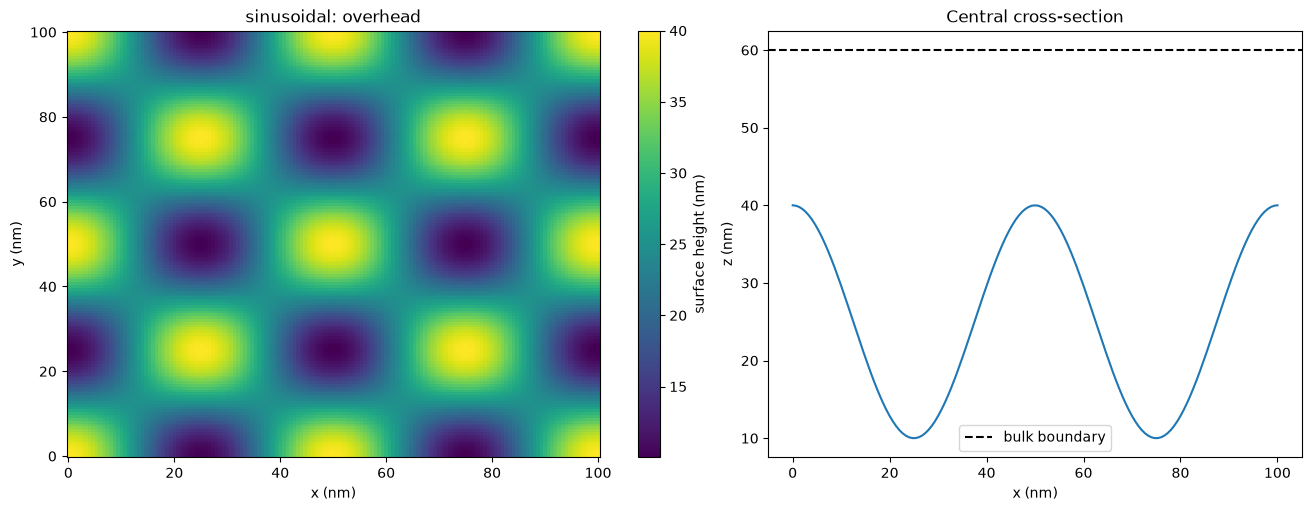

In [98]:
GEOMETRY_NAME = "sinusoidal"  # Options: planar, bowl, curved_sheet, sinusoidal

geometry_options = {
    "planar": planar_height(20 * nm),
    "bowl": spherical_bowl_height(
        radius_m=25 * nm, depth_m=25 * nm,
        center_xy_m=(L_X_M / 2, L_Y_M / 2), rim_z_m=25 * nm,
    ),
    "curved_sheet": cylindrically_curved_sheet_height(
        radius_m=50 * nm, center_m=L_X_M / 2, axis="y", vertex_z_m=0 * nm,
    ),
    "sinusoidal": sinusoidal_height(
        amplitude_m=15 * nm, wavelength_x_m=L_X_M / 2, wavelength_y_m=L_Y_M / 2,
        mean_z_m=25 * nm,
    ),
}
height_function = geometry_options[GEOMETRY_NAME]

x = np.linspace(0, L_X_M, 151)
y = np.linspace(0, L_Y_M, 151)
X, Y = np.meshgrid(x, y, indexing="ij")
Z = height_function(X, Y)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
surface = axes[0].pcolormesh(X / nm, Y / nm, Z / nm, shading="auto")
fig.colorbar(surface, ax=axes[0], label="surface height (nm)")
axes[0].set(xlabel="x (nm)", ylabel="y (nm)", title=f"{GEOMETRY_NAME}: overhead")
axes[1].plot(x / nm, height_function(x, np.full_like(x, L_Y_M / 2)) / nm)
axes[1].axhline(TOP_Z_M / nm, color="black", linestyle="--", label="bulk boundary")
axes[1].set(xlabel="x (nm)", ylabel="z (nm)", title="Central cross-section")
axes[1].legend()
plt.show()

## 4. Equilibrium gross association rate over the selected surface

At equilibrium the net diffusive flux is zero. The one-way gross receptor-association rate is nevertheless nonzero and is balanced by the gross dissociation rate. For uniform free concentration and receptor chemistry, each equal true-area element has the same association-rate density,

$$j_{on}=k_{on}C_{bulk}\rho_{R,free}.$$

With `EQUILIBRIUM_K_OFF_S = None`, the calculation uses the low-occupancy approximation $\rho_{R,free}=\rho_R$. Set a numerical $k_{off}$ to account for equilibrium receptor occupancy through $K_D=k_{off}/k_{on}$. Geometry then changes the total rate through true surface area and any explicitly supplied spatial receptor-density variation—not through equilibrium diffusion accessibility.

,value
C_bulk_M,1.000000e-09
true_surface_area_m2,1.642775e-14
projected_area_m2,1.000000e-14
area_enlargement,1.642775e+00
free_receptor_fraction,1.000000e+00
gross_association_rate_events_s,8.213875e+00
gross_association_rate_mol_s,1.363946e-23
net_equilibrium_flux_mol_s,0.000000e+00


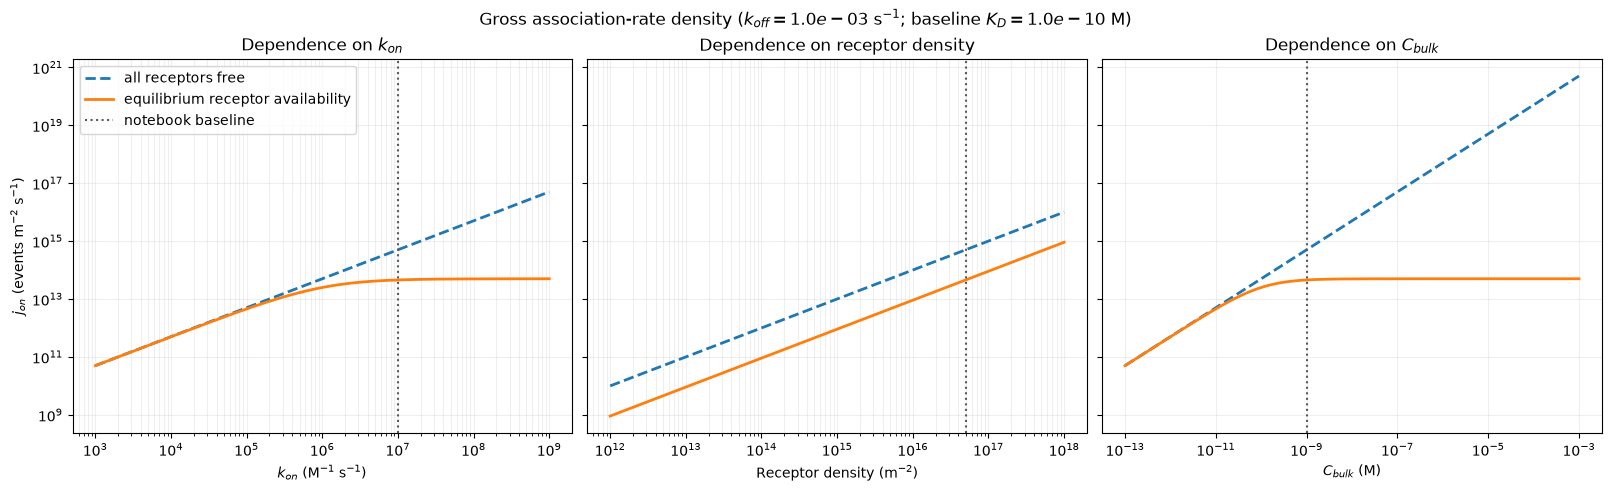

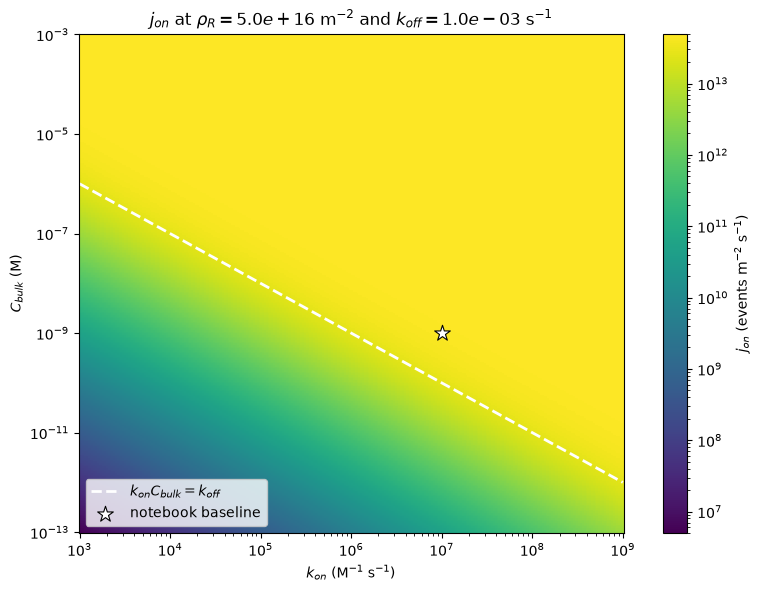

In [99]:
EQUILIBRIUM_K_OFF_S = None  # e.g. 1e-3 to include Langmuir receptor availability
DEPENDENCE_K_OFF_S = 1e-3  # fixed k_off used for the equilibrium-availability comparison curves
EQUILIBRIUM_SURFACE_NX = 150
EQUILIBRIUM_SURFACE_NY = 150

equilibrium_delivery = calculate_equilibrium_surface_delivery(
    height_function,
    Lx_m=L_X_M, Ly_m=L_Y_M,
    c_bulk_mol_m3=C_BULK_MOL_M3,
    k_on_M_inv_s=K_ON_M_INV_S,
    receptor_density_m2=RECEPTOR_DENSITY_M2,
    k_off_s=EQUILIBRIUM_K_OFF_S,
    nx=EQUILIBRIUM_SURFACE_NX, ny=EQUILIBRIUM_SURFACE_NY,
)

equilibrium_delivery_summary = pd.Series({
    'C_bulk_M': equilibrium_delivery.c_bulk_M,
    'true_surface_area_m2': equilibrium_delivery.surface_area_m2,
    'projected_area_m2': equilibrium_delivery.projected_area_m2,
    'area_enlargement': equilibrium_delivery.surface_area_m2 / equilibrium_delivery.projected_area_m2,
    'free_receptor_fraction': equilibrium_delivery.free_receptor_fraction,
    'gross_association_rate_events_s': equilibrium_delivery.total_association_rate_s,
    'gross_association_rate_mol_s': equilibrium_delivery.total_association_rate_mol_s,
    'net_equilibrium_flux_mol_s': 0.0,
}, name=GEOMETRY_NAME)
display(equilibrium_delivery_summary.to_frame('value'))

def gross_association_density(k_on_M_inv_s, c_bulk_M, receptor_density_m2, k_off_s=None):
    low_occupancy_rate = k_on_M_inv_s * c_bulk_M * receptor_density_m2
    if k_off_s is None:
        return low_occupancy_rate
    free_fraction = k_off_s / (k_off_s + k_on_M_inv_s * c_bulk_M)
    return low_occupancy_rate * free_fraction

k_on_values = np.logspace(3, 9, 300)
density_values = np.logspace(12, 18, 300)
concentration_values_M = np.logspace(-13, -3, 300)
baseline_concentration_M = C_BULK_MOL_M3 / 1000.0

parameter_sweeps = [
    (k_on_values,
     gross_association_density(k_on_values, baseline_concentration_M, RECEPTOR_DENSITY_M2),
     gross_association_density(k_on_values, baseline_concentration_M, RECEPTOR_DENSITY_M2, DEPENDENCE_K_OFF_S),
     K_ON_M_INV_S, r'$k_{on}$ (M$^{-1}$ s$^{-1}$)', r'Dependence on $k_{on}$'),
    (density_values,
     gross_association_density(K_ON_M_INV_S, baseline_concentration_M, density_values),
     gross_association_density(K_ON_M_INV_S, baseline_concentration_M, density_values, DEPENDENCE_K_OFF_S),
     RECEPTOR_DENSITY_M2, r'Receptor density (m$^{-2}$)', 'Dependence on receptor density'),
    (concentration_values_M,
     gross_association_density(K_ON_M_INV_S, concentration_values_M, RECEPTOR_DENSITY_M2),
     gross_association_density(K_ON_M_INV_S, concentration_values_M, RECEPTOR_DENSITY_M2, DEPENDENCE_K_OFF_S),
     baseline_concentration_M, r'$C_{bulk}$ (M)', r'Dependence on $C_{bulk}$'),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True, sharey=True)
for ax, (x_values, low_rate, equilibrium_rate, baseline, xlabel, title) in zip(axes, parameter_sweeps):
    ax.loglog(x_values, low_rate, linestyle='--', linewidth=2, label='all receptors free')
    ax.loglog(x_values, equilibrium_rate, linewidth=2, label='equilibrium receptor availability')
    ax.axvline(baseline, color='0.35', linestyle=':', linewidth=1.5, label='notebook baseline')
    ax.set(xlabel=xlabel, title=title)
    ax.grid(True, which='both', alpha=0.2)
axes[0].set_ylabel(r'$j_{on}$ (events m$^{-2}$ s$^{-1}$)')
axes[0].legend()
baseline_kd_M = DEPENDENCE_K_OFF_S / K_ON_M_INV_S
fig.suptitle(
    rf'Gross association-rate density ($k_{{off}}={DEPENDENCE_K_OFF_S:.1e}$ s$^{{-1}}$; '
    rf'baseline $K_D={baseline_kd_M:.1e}$ M)'
)
plt.show()

# Joint dependence on k_on and bulk concentration at fixed receptor density.
K_ON_GRID, C_BULK_GRID_M = np.meshgrid(k_on_values, concentration_values_M)
J_ON_GRID = gross_association_density(
    K_ON_GRID, C_BULK_GRID_M, RECEPTOR_DENSITY_M2, DEPENDENCE_K_OFF_S
)
fig, ax = plt.subplots(figsize=(7.5, 5.8), constrained_layout=True)
heatmap = ax.pcolormesh(
    K_ON_GRID, C_BULK_GRID_M, J_ON_GRID, shading='auto', cmap='viridis',
    norm=LogNorm(vmin=np.nanmin(J_ON_GRID[J_ON_GRID > 0]), vmax=np.nanmax(J_ON_GRID)),
)
transition_c_M = DEPENDENCE_K_OFF_S / k_on_values
ax.plot(
    k_on_values, transition_c_M, color='white', linestyle='--', linewidth=2,
    label=r'$k_{on}C_{bulk}=k_{off}$',
)
ax.scatter(
    [K_ON_M_INV_S], [baseline_concentration_M], marker='*', s=140,
    facecolor='white', edgecolor='black', linewidth=0.8, label='notebook baseline', zorder=3,
)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set(
    xlabel=r'$k_{on}$ (M$^{-1}$ s$^{-1}$)', ylabel=r'$C_{bulk}$ (M)',
    title=rf'$j_{{on}}$ at $\rho_R={RECEPTOR_DENSITY_M2:.1e}$ m$^{{-2}}$ and $k_{{off}}={DEPENDENCE_K_OFF_S:.1e}$ s$^{{-1}}$',
)
fig.colorbar(heatmap, ax=ax, label=r'$j_{on}$ (events m$^{-2}$ s$^{-1}$)')
ax.legend(loc='lower left')
plt.show()


## 5. Construct the mapped tetrahedral fluid mesh

The lower mesh boundary follows the sensor; the upper boundary remains planar. Opposite lateral faces retain matching nodes for the periodic multipoint constraints.

In [100]:
%%script false --no-raise-error
# Temporarily disabled: FEA mesh construction. Remove the line above to re-enable.
mesh_bundle = create_height_field_mesh(height_function, MESH, comm=COMM)
domain = mesh_bundle.domain
if COMM.rank == 0:
    print(f"Local mesh coordinates: {domain.geometry.x.shape[0]:,}")
    print(f"Local tetrahedra: {domain.topology.index_map(domain.topology.dim).size_local:,}")

## 6. Solve the accessibility and finite-reactivity problems

The accessibility calculation uses the exact perfectly absorbing Dirichlet limit. The limited-reactivity calculation uses the Robin coefficient derived from receptor density and intrinsic $k_{on}$. Both use the same mesh and periodic constraints.

In [101]:
%%script false --no-raise-error
# Temporarily disabled: steady FEA solves. Remove the line above to re-enable.
accessibility_config = DiffusionCaptureConfig(
    D_m2_s=D_M2_S, c_bulk_mol_m3=C_BULK_MOL_M3,
    surface_mode="perfect_absorber",
)
reactive_config = DiffusionCaptureConfig(
    D_m2_s=D_M2_S, c_bulk_mol_m3=C_BULK_MOL_M3,
    surface_mode="finite_reactivity", kappa_m_s=KAPPA_M_S,
)

accessibility_result = solve_steady_capture(mesh_bundle, accessibility_config)
reactive_result = solve_steady_capture(mesh_bundle, reactive_config)

summary = pd.DataFrame([
    result_summary(accessibility_result),
    result_summary(reactive_result),
]).set_index("surface_mode")
summary.loc["finite_reactivity", "utilization_vs_perfect_absorber"] = (
    reactive_result.capture_rate_m3_s / accessibility_result.capture_rate_m3_s
)
display(summary)

## 7. Visualize concentration and capture flux with Matplotlib

The first panel shows a subsampled 3D concentration field throughout the fluid. The second places the nonzero DG0 capture-flux values from surface-adjacent cells onto the corresponding sensor height field. Increase `MAX_CONCENTRATION_POINTS` for a denser volume rendering.

In [102]:
%%script false --no-raise-error
# Temporarily disabled: FEA field visualization. Remove the line above to re-enable.
if COMM.size != 1:
    raise RuntimeError("The Matplotlib field plot is intended for a one-rank notebook run.")

MAX_CONCENTRATION_POINTS = 50_000
concentration_coordinates = (
    reactive_result.concentration.function_space.tabulate_dof_coordinates()
)
concentration_values = reactive_result.concentration.x.array.real
n_concentration = min(len(concentration_coordinates), len(concentration_values))
concentration_coordinates = concentration_coordinates[:n_concentration]
concentration_values = concentration_values[:n_concentration]
if n_concentration > MAX_CONCENTRATION_POINTS:
    concentration_indices = np.linspace(
        0, n_concentration - 1, MAX_CONCENTRATION_POINTS, dtype=int
    )
else:
    concentration_indices = np.arange(n_concentration)

tdim = domain.topology.dim
n_local_cells = domain.topology.index_map(tdim).size_local
local_cells = np.arange(n_local_cells, dtype=np.int32)
cell_centers = dolfinx_mesh.compute_midpoints(domain, tdim, local_cells)
flux_values = reactive_result.surface_flux_density.x.array.real[:n_local_cells]
surface_measure = reactive_result.surface_boundary_measure.x.array.real[:n_local_cells]
surface_cells = surface_measure > 0
flux_coordinates = cell_centers[surface_cells].copy()
flux_coordinates[:, 2] = height_function(
    flux_coordinates[:, 0], flux_coordinates[:, 1]
)
flux_values = flux_values[surface_cells]

fig = plt.figure(figsize=(16, 6), constrained_layout=True)
ax_concentration = fig.add_subplot(1, 2, 1, projection="3d")
volume_plot = ax_concentration.scatter(
    concentration_coordinates[concentration_indices, 0] / nm,
    concentration_coordinates[concentration_indices, 1] / nm,
    concentration_coordinates[concentration_indices, 2] / nm,
    c=concentration_values[concentration_indices], cmap="viridis",
    s=4, alpha=0.45, linewidths=0, rasterized=True,
)
fig.colorbar(volume_plot, ax=ax_concentration, shrink=0.7, pad=0.08, label=r"$c$ (mol m$^{-3}$)")
ax_concentration.set(
    xlabel="x (nm)", ylabel="y (nm)", zlabel="z (nm)",
    title="Steady analyte concentration",
)
ax_concentration.view_init(elev=28, azim=-58)

ax_flux = fig.add_subplot(1, 2, 2, projection="3d")
flux_plot = ax_flux.scatter(
    flux_coordinates[:, 0] / nm, flux_coordinates[:, 1] / nm,
    flux_coordinates[:, 2] / nm, c=flux_values, cmap="magma",
    s=18, linewidths=0, rasterized=True,
)
fig.colorbar(flux_plot, ax=ax_flux, shrink=0.7, pad=0.08, label=r"$j_{capture}$ (mol m$^{-2}$ s$^{-1}$)")
ax_flux.set(
    xlabel="x (nm)", ylabel="y (nm)", zlabel="z (nm)",
    title="Surface capture-flux density",
)
ax_flux.view_init(elev=35, azim=-60)
fig.suptitle(f"Finite-reactivity FEM solution — {GEOMETRY_NAME}")
plt.show()

## 8. Calibrate and remove bulk-layer height resistance

For a planar Robin surface, the area-normalized transport resistance is $A/k_{capture}=R_0+H/D$. We retain a planar height sweep as a reference and numerical check, but the correction itself uses the selected geometry. The same geometry is solved with several clearances $\Delta z=z_{top}-\max(h)$ above its highest point, and $A/k_{capture}=R_{geometry}+m\Delta z$ is fitted. The zero-clearance intercept $R_{geometry}$ defines the height-corrected capture rate $k_{corrected}=A/R_{geometry}$. This removes the added bulk layer without subtracting a planar resistance from a nonplanar geometry.

This is an extrapolated transport correction, not an equilibrium concentration calculation. Check that resistance is approximately linear over the clearance sweep and include small clearances so the zero-clearance intercept is not a long extrapolation.

In [103]:
%%script false --no-raise-error
# Temporarily disabled: FEA height sweep. Remove the line above to re-enable.
RUN_HEIGHT_CORRECTION = True
PLANAR_GAPS_NM = np.array([20, 30, 45, 60, 90, 130], dtype=float)
GEOMETRY_CLEARANCES_NM = np.array([20, 35, 55, 85], dtype=float)
HEIGHT_SWEEP_NX = min(MESH.nx, 32)
HEIGHT_SWEEP_NY = min(MESH.ny, 32)
HEIGHT_SWEEP_NZ = min(MESH.nz, 24)

if RUN_HEIGHT_CORRECTION:
    projected_area_m2 = L_X_M * L_Y_M
    planar_rows = []
    for gap_nm in PLANAR_GAPS_NM:
        calibration_mesh_config = FEMeshConfig(
            Lx_m=L_X_M, Ly_m=L_Y_M, top_z_m=gap_nm * nm,
            nx=HEIGHT_SWEEP_NX, ny=HEIGHT_SWEEP_NY, nz=HEIGHT_SWEEP_NZ,
            periodic_x=True, periodic_y=True,
        )
        calibration_mesh = create_height_field_mesh(
            planar_height(0.0), calibration_mesh_config, comm=COMM
        )
        calibration_result = solve_steady_capture(calibration_mesh, reactive_config)
        planar_rows.append({
            'gap_nm': gap_nm,
            'capture_rate_m3_s': calibration_result.capture_rate_m3_s,
            'areal_resistance_s_m': projected_area_m2 / calibration_result.capture_rate_m3_s,
            'mass_balance_relative_error': calibration_result.mass_balance_relative_error,
        })
    planar_height_sweep = pd.DataFrame(planar_rows)
    planar_resistance_fit = fit_planar_bulk_resistance(
        planar_height_sweep['gap_nm'].to_numpy() * nm,
        planar_height_sweep['capture_rate_m3_s'].to_numpy(),
        projected_area_m2,
    )

    mean_surface_z_m = float(np.mean(Z))
    current_height_corrected = height_corrected_surface_accessibility(
        capture_rate_m3_s=reactive_result.capture_rate_m3_s,
        projected_area_m2=projected_area_m2,
        top_z_m=TOP_Z_M, mean_surface_z_m=mean_surface_z_m,
        planar_fit=planar_resistance_fit,
    )

    geometry_rows = []
    maximum_surface_z_m = float(np.max(Z))
    for clearance_nm in GEOMETRY_CLEARANCES_NM:
        sweep_top_z_m = maximum_surface_z_m + clearance_nm * nm
        sweep_mesh_config = FEMeshConfig(
            Lx_m=L_X_M, Ly_m=L_Y_M, top_z_m=sweep_top_z_m,
            nx=HEIGHT_SWEEP_NX, ny=HEIGHT_SWEEP_NY, nz=HEIGHT_SWEEP_NZ,
            periodic_x=True, periodic_y=True,
        )
        sweep_mesh = create_height_field_mesh(height_function, sweep_mesh_config, comm=COMM)
        sweep_result = solve_steady_capture(sweep_mesh, reactive_config)
        corrected = height_corrected_surface_accessibility(
            capture_rate_m3_s=sweep_result.capture_rate_m3_s,
            projected_area_m2=projected_area_m2,
            top_z_m=sweep_top_z_m, mean_surface_z_m=mean_surface_z_m,
            planar_fit=planar_resistance_fit,
        )
        geometry_rows.append({
            'top_z_nm': sweep_top_z_m / nm, 'clearance_above_peak_nm': clearance_nm,
            'capture_rate_m3_s': sweep_result.capture_rate_m3_s,
            'mass_balance_relative_error': sweep_result.mass_balance_relative_error,
            **corrected,
        })
    geometry_height_sweep = pd.DataFrame(geometry_rows)
    geometry_resistance_fit = fit_planar_bulk_resistance(
        geometry_height_sweep['clearance_above_peak_nm'].to_numpy() * nm,
        geometry_height_sweep['capture_rate_m3_s'].to_numpy(),
        projected_area_m2,
    )
    geometry_surface_resistance_s_m = geometry_resistance_fit.intercept_s_m
    if geometry_surface_resistance_s_m <= 0:
        raise RuntimeError(
            'The same-geometry zero-clearance resistance is nonpositive. '
            'Inspect linearity, add smaller clearances, or avoid extrapolating this geometry.'
        )
    geometry_corrected_surface_velocity_m_s = 1.0 / geometry_surface_resistance_s_m
    geometry_corrected_capture_rate_m3_s = (
        projected_area_m2 * geometry_corrected_surface_velocity_m_s
    )
    geometry_corrected_map_factor = (
        geometry_corrected_capture_rate_m3_s / reactive_result.capture_rate_m3_s
    )
    geometry_accessibility_vs_planar = (
        planar_resistance_fit.intercept_s_m / geometry_surface_resistance_s_m
    )

    fit_summary = pd.Series({
        'fitted_slope_s_m2': planar_resistance_fit.slope_s_m2,
        'expected_1_over_D_s_m2': 1.0 / D_M2_S,
        'slope_over_expected': planar_resistance_fit.slope_s_m2 * D_M2_S,
        'fitted_planar_surface_resistance_s_m': planar_resistance_fit.intercept_s_m,
        'expected_1_over_kappa_s_m': 1.0 / KAPPA_M_S,
        'fit_r_squared': planar_resistance_fit.r_squared,
        'geometry_resistance_fit_r_squared': geometry_resistance_fit.r_squared,
        'geometry_clearance_slope_s_m2': geometry_resistance_fit.slope_s_m2,
        'geometry_slope_over_expected_1_over_D': geometry_resistance_fit.slope_s_m2 * D_M2_S,
        'geometry_zero_clearance_resistance_s_m': geometry_surface_resistance_s_m,
        'geometry_corrected_surface_velocity_m_s': geometry_corrected_surface_velocity_m_s,
        'geometry_corrected_capture_rate_m3_s': geometry_corrected_capture_rate_m3_s,
        'geometry_accessibility_vs_planar': geometry_accessibility_vs_planar,
        'geometry_corrected_map_factor': geometry_corrected_map_factor,
        **current_height_corrected,
    }, name=GEOMETRY_NAME)
    display(fit_summary.to_frame('value'))
    display(geometry_height_sweep)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
    axes[0].scatter(planar_height_sweep['gap_nm'], planar_height_sweep['areal_resistance_s_m'], label='planar FEM')
    fit_gap_nm = np.linspace(0, PLANAR_GAPS_NM.max() * 1.05, 200)
    axes[0].plot(fit_gap_nm, planar_resistance_fit.predict_areal_resistance(fit_gap_nm * nm), label='linear resistance fit')
    axes[0].set(xlabel='planar bulk-layer height (nm)', ylabel=r'$A/k_{capture}$ (s/m)', title='Planar bulk-resistance calibration')
    axes[0].legend()

    geometry_gap_nm = geometry_height_sweep['clearance_above_peak_nm']
    geometry_resistance = projected_area_m2 / geometry_height_sweep['capture_rate_m3_s']
    axes[1].scatter(geometry_gap_nm, geometry_resistance, label=f'{GEOMETRY_NAME} FEM')
    comparison_gap_nm = np.linspace(0, max(geometry_gap_nm.max(), PLANAR_GAPS_NM.max()), 200)
    axes[1].plot(comparison_gap_nm, geometry_resistance_fit.predict_areal_resistance(comparison_gap_nm * nm), label=f'{GEOMETRY_NAME} fit')
    axes[1].plot(comparison_gap_nm, planar_resistance_fit.predict_areal_resistance(comparison_gap_nm * nm), linestyle='--', label='planar fit')
    axes[1].scatter([0], [geometry_surface_resistance_s_m], color='black', marker='*', s=100, label='corrected intercept')
    axes[1].set(xlabel='bulk clearance above surface peak (nm)', ylabel=r'$A/k_{capture}$ (s/m)', title=f'Same-geometry height correction — {GEOMETRY_NAME}')
    axes[1].legend()
    plt.show()


### Uncorrected versus same-geometry height-corrected capture-velocity maps

The top row shows the raw local velocity $v_{app}(\mathbf{s})=j(\mathbf{s})/C_{bulk}$ at the configured top boundary. The bottom row rescales it so that its integral equals the zero-clearance capture rate obtained from the same geometry's resistance-versus-clearance fit. Each row has its own shared color scale. The spatial pattern is unchanged; the correction removes the fitted resistance of the added bulk layer from the integrated magnitude.

In [104]:
%%script false --no-raise-error
# Temporarily disabled: corrected FEA maps. Remove the line above to re-enable.
if not RUN_HEIGHT_CORRECTION:
    raise RuntimeError('Run the bulk-layer height calibration before plotting the corrected surface map.')
if not np.isfinite(geometry_corrected_map_factor) or geometry_corrected_map_factor <= 0:
    raise RuntimeError('The same-geometry correction factor is invalid; inspect the resistance fit.')

tdim = domain.topology.dim
n_local_cells = domain.topology.index_map(tdim).size_local
local_cells = np.arange(n_local_cells, dtype=np.int32)
corrected_cell_centers = dolfinx_mesh.compute_midpoints(domain, tdim, local_cells)
corrected_surface_measure = reactive_result.surface_boundary_measure.x.array.real[:n_local_cells]
corrected_surface_cells = corrected_surface_measure > 0
corrected_coordinates = corrected_cell_centers[corrected_surface_cells].copy()
corrected_coordinates[:, 2] = height_function(corrected_coordinates[:, 0], corrected_coordinates[:, 1])
raw_local_velocity_m_s = (
    reactive_result.surface_flux_density.x.array.real[:n_local_cells][corrected_surface_cells]
    / C_BULK_MOL_M3
)
bulk_correction_factor = geometry_corrected_map_factor
corrected_local_velocity_m_s = raw_local_velocity_m_s * bulk_correction_factor

fig = plt.figure(figsize=(15, 11), constrained_layout=True)

ax_raw_3d = fig.add_subplot(2, 2, 1, projection='3d')
raw_3d = ax_raw_3d.scatter(
    corrected_coordinates[:, 0] / nm, corrected_coordinates[:, 1] / nm,
    corrected_coordinates[:, 2] / nm, c=raw_local_velocity_m_s,
    cmap='magma', s=18, linewidths=0, rasterized=True,
)
ax_raw_3d.set(xlabel='x (nm)', ylabel='y (nm)', zlabel='z (nm)', title='Uncorrected — 3D')
ax_raw_3d.view_init(elev=35, azim=-60)
ax_raw_xy = fig.add_subplot(2, 2, 2)
raw_xy = ax_raw_xy.scatter(
    corrected_coordinates[:, 0] / nm, corrected_coordinates[:, 1] / nm,
    c=raw_local_velocity_m_s, cmap='magma', s=18, linewidths=0, rasterized=True,
    vmin=raw_3d.get_clim()[0], vmax=raw_3d.get_clim()[1],
)
ax_raw_xy.set_aspect('equal')
ax_raw_xy.set(xlabel='x (nm)', ylabel='y (nm)', title='Uncorrected — overhead')
fig.colorbar(raw_xy, ax=[ax_raw_3d, ax_raw_xy], shrink=0.78, pad=0.04, label='apparent capture velocity (m/s)')

ax_corrected_3d = fig.add_subplot(2, 2, 3, projection='3d')
corrected_3d = ax_corrected_3d.scatter(
    corrected_coordinates[:, 0] / nm, corrected_coordinates[:, 1] / nm,
    corrected_coordinates[:, 2] / nm, c=corrected_local_velocity_m_s,
    cmap='magma', s=18, linewidths=0, rasterized=True,
)
ax_corrected_3d.set(xlabel='x (nm)', ylabel='y (nm)', zlabel='z (nm)', title='Same-geometry corrected — 3D')
ax_corrected_3d.view_init(elev=35, azim=-60)
ax_corrected_xy = fig.add_subplot(2, 2, 4)
corrected_xy = ax_corrected_xy.scatter(
    corrected_coordinates[:, 0] / nm, corrected_coordinates[:, 1] / nm,
    c=corrected_local_velocity_m_s, cmap='magma', s=18, linewidths=0, rasterized=True,
    vmin=corrected_3d.get_clim()[0], vmax=corrected_3d.get_clim()[1],
)
ax_corrected_xy.set_aspect('equal')
ax_corrected_xy.set(xlabel='x (nm)', ylabel='y (nm)', title='Same-geometry corrected — overhead')
fig.colorbar(corrected_xy, ax=[ax_corrected_3d, ax_corrected_xy], shrink=0.78, pad=0.04, label='height-corrected capture velocity (m/s)')
fig.suptitle(f'{GEOMETRY_NAME}: uncorrected vs same-geometry height correction (factor = {bulk_correction_factor:.3g})')
plt.show()

print(f"Raw integrated capture coefficient: {reactive_result.capture_rate_m3_s:.4e} m^3/s")
print(f"Same-geometry height-corrected capture coefficient: {geometry_corrected_capture_rate_m3_s:.4e} m^3/s")
print(f"Height-corrected projected surface velocity: {geometry_corrected_surface_velocity_m_s:.4e} m/s")
print(f"Corrected accessibility relative to the planar intercept: {geometry_accessibility_vs_planar:.4f}")
display(pd.DataFrame({
    'uncorrected_m_s': [np.min(raw_local_velocity_m_s), np.median(raw_local_velocity_m_s), np.max(raw_local_velocity_m_s)],
    'same_geometry_corrected_m_s': [np.min(corrected_local_velocity_m_s), np.median(corrected_local_velocity_m_s), np.max(corrected_local_velocity_m_s)],
}, index=['minimum', 'median', 'maximum']))


## 9. Mesh-convergence check

Run at least three resolutions before interpreting geometry effects. The example below is disabled by default because it performs six additional three-dimensional solves.

In [105]:
%%script false --no-raise-error
# Temporarily disabled: FEA mesh-convergence study. Remove the line above to re-enable.
RUN_MESH_CONVERGENCE = True

if RUN_MESH_CONVERGENCE:
    convergence_rows = []
    for nx, ny, nz in [(16, 16, 12), (24, 24, 18), (32, 32, 24)]:
        current_mesh_config = FEMeshConfig(
            Lx_m=L_X_M, Ly_m=L_Y_M, top_z_m=TOP_Z_M,
            nx=nx, ny=ny, nz=nz, periodic_x=True, periodic_y=True,
        )
        current_mesh = create_height_field_mesh(height_function, current_mesh_config, comm=COMM)
        for current_config in [accessibility_config, reactive_config]:
            current_result = solve_steady_capture(current_mesh, current_config)
            convergence_rows.append({
                "nx": nx, "ny": ny, "nz": nz,
                **result_summary(current_result),
            })
    convergence = pd.DataFrame(convergence_rows)
    display(convergence)
    for mode, group in convergence.groupby("surface_mode"):
        plt.plot(group["nx"], group["capture_rate_m3_s"], marker="o", label=mode)
    plt.xlabel("lateral mesh subdivisions")
    plt.ylabel(r"$k_{capture}$ (m$^3$/s)")
    plt.legend()
    plt.show()

## 10. Export fields and summaries

The XDMF files can be opened in ParaView. Export is collective under MPI; the JSON summary is written by rank zero.

In [106]:
%%script false --no-raise-error
# Temporarily disabled: FEA export. Remove the line above to re-enable.
SAVE_RESULTS = False
OUTPUT_ROOT = PROJECT_ROOT / "data/fea_capture" / GEOMETRY_NAME

if SAVE_RESULTS:
    write_fea_result(accessibility_result, OUTPUT_ROOT / "perfect_absorber")
    write_fea_result(reactive_result, OUTPUT_ROOT / "finite_reactivity")
    if COMM.rank == 0:
        summary.to_csv(OUTPUT_ROOT / "comparison.csv")
        print(f"Saved results under {OUTPUT_ROOT}")